# 🧠 LSTM Time Series Forecasting
> **Luận văn tốt nghiệp** | EDA · Feature Engineering · LSTM Model  
> Dataset: 5.3M dòng · 36,923 groups · 4 horizons · 86 features

---
## Mục lục
1. [Config & Imports](#1)
2. [EDA](#2)
3. [Feature Engineering](#3)
4. [Build Sequences](#4)
5. [LSTM Model](#5)
6. [Training](#6)
7. [Inference & Submission](#7)
8. [So sánh LightGBM](#8)

In [1]:
# ============================================================
# 1. CONFIG & IMPORTS
# ============================================================
import gc, warnings, json
from pathlib import Path
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torch.cuda.amp import GradScaler, autocast
from sklearn.preprocessing import LabelEncoder, RobustScaler

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)

# ── Paths ──────────────────────────────────────────────────
DATA_DIR   = Path('/kaggle/input/competitions/ts-forecasting')
OUTPUT_DIR = Path('/kaggle/working')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Schema ────────────────────────────────────────────────
ID_COL     = 'id'
TIME_COL   = 'ts_index'
TARGET_COL = 'y_target'
WEIGHT_COL = 'weight'
GROUP_COLS = ['code', 'sub_code', 'sub_category', 'horizon']
BASE_COLS  = ['code', 'sub_code', 'sub_category']   # không có horizon
CAT_COLS   = ['code', 'sub_code', 'sub_category']
HORIZONS   = [1, 3, 10, 25]
H2I        = {1: 0, 3: 1, 10: 2, 25: 3}

# ── LSTM Hyperparameters (tối ưu cho T4 14.6GB) ────────────────
# SEQ_LEN=30: EDA cho thấy autocorr giảm về 0 sau lag_3, period mạnh nhất = 20
SEQ_LEN      = 30
HIDDEN_DIM1  = 256    # Tăng từ 128 → 256 để học được pattern phức tạp
HIDDEN_DIM2  = 128    # Tăng từ 64 → 128
FC_DIM       = 128    # Tăng từ 64 → 128
DROPOUT      = 0.3
N_OUTPUTS    = 4

# ── Training Config ───────────────────────────────────────
BATCH_SIZE    = 512    # Giảm xuống 512 để fit VRAM với model lớn hơn
LR_MAX        = 3e-4   # OneCycleLR max_lr: safe hơn 1e-3
LR_INIT       = 1e-5   # Bắt đầu rất thấp — warmup từ từ
WEIGHT_DECAY  = 1e-4
N_EPOCHS      = 50
PATIENCE      = 8
VAL_THRESHOLD = 3000

# RAM budget Kaggle T4 = ~13 GB usable
# Train: 5.3M rows x 94 cols = ~4.9 GB ban đầu
# Sau FE: giảm xuống vì dùng float32 + chỉ giữ features cần thiết
# Sequences: MAX_SEQ x 30 x n_feat x 4 bytes
# 300k x 30 x 22 x 4 = 0.79 GB — an toàn
MAX_SEQ_TRAIN = 300_000
MAX_SEQ_VAL   = 80_000

RANDOM_SEED   = 42
APPLY_CALIB   = True

DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print('=' * 60)
print(f'  Device      : {DEVICE}')
print(f'  AMP         : {USE_AMP}')
print(f'  HIDDEN      : {HIDDEN_DIM1} → {HIDDEN_DIM2}')
print(f'  BATCH_SIZE  : {BATCH_SIZE}')
print(f'  MAX_TRAIN   : {MAX_SEQ_TRAIN:,} sequences')
if DEVICE.type == 'cuda':
    vram = torch.cuda.get_device_properties(0).total_memory / 1024**3
    print(f'  GPU         : {torch.cuda.get_device_name(0)}')
    print(f'  VRAM        : {vram:.1f} GB')
print('=' * 60)

  Device      : cuda
  AMP         : True
  HIDDEN      : 256 → 128
  BATCH_SIZE  : 512
  MAX_TRAIN   : 300,000 sequences
  GPU         : Tesla T4
  VRAM        : 14.6 GB


In [2]:
# ============================================================
# 2. METRIC & CALIBRATION
# ============================================================
def weighted_rmse_score(y_true, y_pred, w) -> float:
    """Competition metric: sqrt(1 - clip(sum_w(y-p)^2 / sum_w*y^2, 0,1))"""
    y_true = np.asarray(y_true, np.float64).ravel()
    y_pred = np.asarray(y_pred, np.float64).ravel()
    w      = np.asarray(w,      np.float64).ravel()
    denom  = np.sum(w * y_true**2)
    if denom <= 0: return 0.0
    return float(np.sqrt(1.0 - np.clip(np.sum(w*(y_true-y_pred)**2)/denom, 0, 1)))

def weighted_linear_calibration(y_true, y_pred, w):
    """Tìm a,b: pred_calib = a*pred + b  (weighted OLS)"""
    ws = w.sum()
    if ws <= 0: return 1.0, 0.0
    pm = (w*y_pred).sum()/ws;  ym = (w*y_true).sum()/ws
    cov = (w*(y_pred-pm)*(y_true-ym)).sum()
    var = (w*(y_pred-pm)**2).sum()
    if var <= 1e-12: return 1.0, 0.0
    a = float(cov/var);  b = float(ym - a*pm)
    return a, b

# Sanity
assert abs(weighted_rmse_score([1,2,3],[1,2,3],[1,1,1]) - 1.0) < 1e-9
assert abs(weighted_rmse_score([1,2,3],[0,0,0],[1,1,1]))       < 1e-9
print('✅ Metric OK')

✅ Metric OK


---
## 📊 Phần 1: EDA (Exploratory Data Analysis)

In [3]:
# ============================================================
# EDA-1: LOAD & CẤU TRÚC DỮ LIỆU
# ============================================================
print('Loading data...')
train = pd.read_parquet(DATA_DIR / 'train.parquet')
test  = pd.read_parquet(DATA_DIR / 'test.parquet')

def mem_mb(df): return df.memory_usage(deep=True).sum() / 1024**2

print(f'  TRAIN: {train.shape[0]:>10,} rows x {train.shape[1]} cols | {mem_mb(train):.0f} MB')
print(f'  TEST : {test.shape[0]:>10,} rows x {test.shape[1]} cols | {mem_mb(test):.0f} MB')

NON_FEAT  = set([ID_COL, TIME_COL, TARGET_COL, WEIGHT_COL] + GROUP_COLS)
RAW_FEATS = [c for c in train.columns if c not in NON_FEAT]
print(f'  Raw features: {len(RAW_FEATS)}')
print(f'  Train-only cols: {[c for c in train.columns if c not in test.columns]}')
print()
print('Cấu trúc một dòng:')
display(train.head(4)[[ID_COL, 'code', 'sub_code', 'sub_category', 'horizon',
                        TIME_COL, TARGET_COL, WEIGHT_COL,
                        'feature_a', 'feature_b', 'feature_c']])

Loading data...
  TRAIN:  5,337,414 rows x 94 cols | 4913 MB
  TEST :  1,447,107 rows x 92 cols | 1310 MB
  Raw features: 86
  Train-only cols: ['y_target', 'weight']

Cấu trúc một dòng:


,id,code,sub_code,sub_category,horizon,ts_index,y_target,weight,feature_a,feature_b,feature_c
0,W2MW3G2L__J0G2B0KU__PZ9S1Z4V__25__89,W2MW3G2L,J0G2B0KU,PZ9S1Z4V,25,89,-0.551324,40.982572,29,16.364093,7.464023
1,W2MW3G2L__J0G2B0KU__PZ9S1Z4V__1__89,W2MW3G2L,J0G2B0KU,PZ9S1Z4V,1,89,-0.315583,150.075406,53,2.858806,5.050617
2,W2MW3G2L__J0G2B0KU__PZ9S1Z4V__3__89,W2MW3G2L,J0G2B0KU,PZ9S1Z4V,3,89,-0.362894,115.953552,51,9.585452,1.076268
3,W2MW3G2L__J0G2B0KU__PZ9S1Z4V__10__89,W2MW3G2L,J0G2B0KU,PZ9S1Z4V,10,89,-0.667023,64.573073,44,8.840588,15.034634


In [4]:
# ============================================================
# EDA-2: CHẤT LƯỢNG DỮ LIỆU
# ============================================================
print('\u2500\u2500 Missing values (TRAIN) \u2500\u2500')
miss = (train[RAW_FEATS].isna().mean() * 100).sort_values(ascending=False)
miss_nonzero = miss[miss > 0]
print(f'  Features không có NaN  : {(miss == 0).sum()}')
print(f'  Features có NaN        : {(miss > 0).sum()}')
print(f'  Features > 5% NaN      : {(miss > 5).sum()}')
print(f'  Top 5 missing:')
display(miss_nonzero.head(5).rename('missing_%').to_frame())

print('\n\u2500\u2500 Missing values (TEST) \u2500\u2500')
miss_te = (test[RAW_FEATS].isna().mean() * 100).sort_values(ascending=False)
# Chú ý: feature_w/x/y/z có 0% NaN trong train nhưng 38.6% trong test!
drift_miss = []
for c in RAW_FEATS:
    tr_m = miss[c] if c in miss else 0
    te_m = miss_te[c] if c in miss_te else 0
    if abs(te_m - tr_m) > 10:
        drift_miss.append({'feature': c, 'train_miss%': round(tr_m,1), 'test_miss%': round(te_m,1)})
if drift_miss:
    print(f'  ⚠️  Features có drift missing trầm trọng (test - train > 10%): {len(drift_miss)}')
    display(pd.DataFrame(drift_miss))

print('\n\u2500\u2500 Duplicate check \u2500\u2500')
print(f'  Duplicate rows train: {train.duplicated().sum():,}')
print(f'  Near-constant features: ', end='')
nc = [c for c in RAW_FEATS if train[c].value_counts(normalize=True).iloc[0] > 0.995]
print(f'{nc if nc else "None ✅"}')

── Missing values (TRAIN) ──
  Features không có NaN  : 38
  Features có NaN        : 48
  Features > 5% NaN      : 5
  Top 5 missing:


,missing_%
feature_at,12.471882
feature_by,11.019194
feature_ay,8.541964
feature_cd,7.496402
feature_ce,5.167840



── Missing values (TEST) ──
  ⚠️  Features có drift missing trầm trọng (test - train > 10%): 4


,feature,train_miss%,test_miss%
0,feature_w,0.1,38.6
1,feature_x,0.1,38.6
2,feature_y,0.1,38.6
3,feature_z,0.1,38.6



── Duplicate check ──
  Duplicate rows train: 0
  Near-constant features: None ✅


── Group Analysis ──
  code       : 23 unique
  sub_code   : 180 unique
  sub_category: 5 unique
  horizon    : [np.int32(1), np.int32(3), np.int32(10), np.int32(25)]

  Groups trong TRAIN   : 36,923
  Groups trong TEST    : 11,039
  Groups mới trong TEST: 9,164 (83% của test) ← cold start!

  Phân phối kích thước group (train):
    min=1  P25=104  median=166  P75=194  max=213


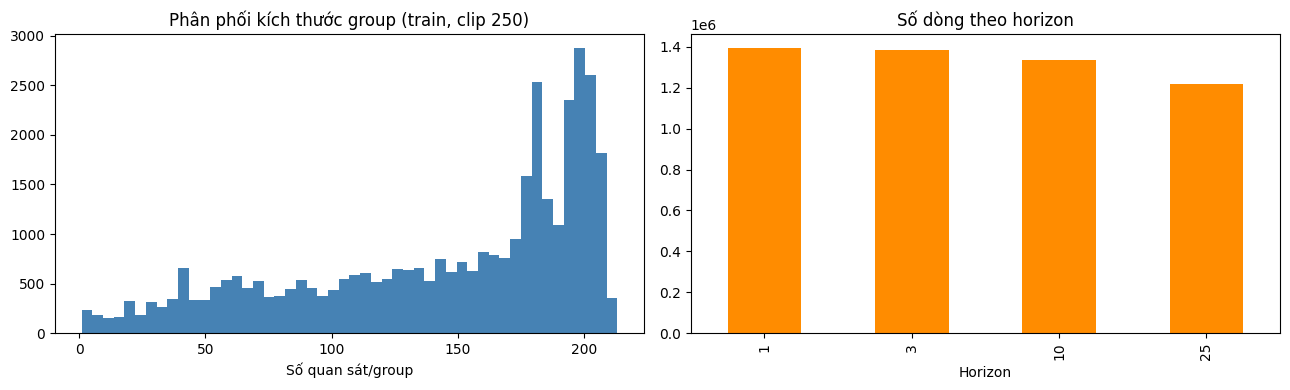

In [5]:
# ============================================================
# EDA-3: PHÂN TÍCH NHÓM (GROUP ANALYSIS)
# ============================================================
print('\u2500\u2500 Group Analysis \u2500\u2500')
print(f'  code       : {train["code"].nunique()} unique')
print(f'  sub_code   : {train["sub_code"].nunique()} unique')
print(f'  sub_category: {train["sub_category"].nunique()} unique')
print(f'  horizon    : {sorted(train["horizon"].unique())}')

train['__gid__'] = train[BASE_COLS + ['horizon']].astype(str).agg('__'.join, axis=1)
test['__gid__']  = test[BASE_COLS  + ['horizon']].astype(str).agg('__'.join, axis=1)
n_tr = train['__gid__'].nunique()
n_te = test['__gid__'].nunique()
n_new = len(set(test['__gid__']) - set(train['__gid__']))

print(f'\n  Groups trong TRAIN   : {n_tr:,}')
print(f'  Groups trong TEST    : {n_te:,}')
print(f'  Groups mới trong TEST: {n_new:,} ({n_new/n_te*100:.0f}% của test) ← cold start!')

gs = train.groupby(BASE_COLS + ['horizon']).size()
print(f'\n  Phân phối kích thước group (train):')
print(f'    min={gs.min()}  P25={gs.quantile(.25):.0f}  median={gs.median():.0f}  '
      f'P75={gs.quantile(.75):.0f}  max={gs.max()}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(gs[gs <= 250], bins=50, color='steelblue', edgecolor='none')
axes[0].set_title('Phân phối kích thước group (train, clip 250)')
axes[0].set_xlabel('Số quan sát/group')
train.groupby('horizon').size().plot(kind='bar', ax=axes[1], color='darkorange', edgecolor='none')
axes[1].set_title('Số dòng theo horizon')
axes[1].set_xlabel('Horizon')
plt.tight_layout()
plt.show()

In [6]:
# ============================================================
# EDA-4: CẤU TRÚC THỜI GIAN
# ============================================================
print('\u2500\u2500 Time Structure \u2500\u2500')
print(f'  TRAIN: ts {train[TIME_COL].min()} \u2192 {train[TIME_COL].max()} '
      f'({train[TIME_COL].nunique():,} unique steps)')
print(f'  TEST : ts {test[TIME_COL].min()} \u2192 {test[TIME_COL].max()} '
      f'({test[TIME_COL].nunique():,} unique steps)')
print(f'  Overlap: 0 steps (test ho\u00e0n to\u00e0n sau train)')

# Within-group gaps
tmp = train[BASE_COLS + ['horizon', TIME_COL]].sort_values(BASE_COLS + ['horizon', TIME_COL])
tmp['gap'] = tmp.groupby(BASE_COLS + ['horizon'])[TIME_COL].diff()
gaps = tmp['gap'].dropna()
p99 = gaps.quantile(0.99)
print(f'\n  Within-group gaps:')
print(f'    median={gaps.median():.0f}  mean={gaps.mean():.3f}  max={gaps.max():.0f}')
print(f'    Gaps > P99={p99:.0f}: {(gaps > p99).sum():,} \u2190 ⚠️ nhịng chỗ n\u00e0y lag features bị sai')
del tmp; gc.collect()

── Time Structure ──
  TRAIN: ts 1 → 3601 (3,601 unique steps)
  TEST : ts 3602 → 4376 (775 unique steps)
  Overlap: 0 steps (test hoàn toàn sau train)

  Within-group gaps:
    median=1  mean=1.057  max=142
    Gaps > P99=2: 25,680 ← ⚠️ nhịng chỗ này lag features bị sai


63

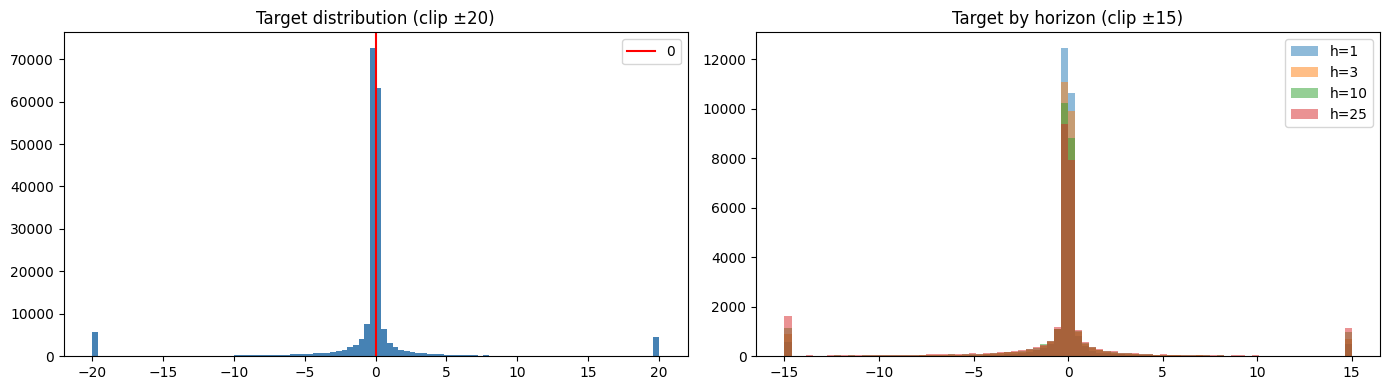

Stats theo horizon:
   h |      count |     mean |      std |   median |   kurtosis
------------------------------------------------------------
   1 |  1,394,653 |  -0.0827 |  11.6997 | -0.000243 |      528.5
   3 |  1,385,816 |  -0.2524 |  19.3612 | -0.000400 |      243.8
  10 |  1,337,236 |  -0.7760 |  33.8421 | -0.000917 |      176.8
  25 |  1,219,709 |  -1.6819 |  52.8233 | -0.001865 |      141.5

💡 Key insight: target median ≈0 cho mọi horizon
   Kurtosis rất cao (fat tails) → sử dụng Huber loss thay vì MSE thuần
   std tăng theo horizon (h=1:11.7 → h=25:52.8) → normalize target theo horizon


In [7]:
# ============================================================
# EDA-5: PHÂN PHỐI TARGET
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Clip để nhìn rõ phần giữa phân phối
sample = train[TARGET_COL].dropna().sample(200_000, random_state=42)
axes[0].hist(sample.clip(-20, 20), bins=100, color='steelblue', edgecolor='none')
axes[0].set_title('Target distribution (clip \u00b120)')
axes[0].axvline(0, color='red', lw=1.5, label='0')
axes[0].legend()

colors_h = {1:'#1f77b4', 3:'#ff7f0e', 10:'#2ca02c', 25:'#d62728'}
for h in HORIZONS:
    vals = train.loc[train['horizon']==h, TARGET_COL].dropna().sample(30_000, random_state=42)
    axes[1].hist(vals.clip(-15, 15), bins=80, alpha=0.5, label=f'h={h}', color=colors_h[h], edgecolor='none')
axes[1].set_title('Target by horizon (clip \u00b115)')
axes[1].legend()
plt.tight_layout(); plt.show()

print('Stats theo horizon:')
print(f'{"h":>4} | {"count":>10} | {"mean":>8} | {"std":>8} | {"median":>8} | {"kurtosis":>10}')
print('-'*60)
for h in HORIZONS:
    s = train.loc[train['horizon']==h, TARGET_COL]
    print(f'{h:>4} | {len(s):>10,} | {s.mean():>8.4f} | {s.std():>8.4f} | {s.median():>8.6f} | {s.kurt():>10.1f}')

print('\n💡 Key insight: target median \u22480 cho mọi horizon')
print('   Kurtosis rất cao (fat tails) \u2192 sử dụng Huber loss thay vì MSE thuần')
print('   std tăng theo horizon (h=1:11.7 \u2192 h=25:52.8) \u2192 normalize target theo horizon')

In [8]:
# ============================================================
# EDA-6: LAG & SEASONALITY
# ============================================================
print('\u2500\u2500 Autocorrelation (lag features vs target) \u2500\u2500')
# Chọn subset đủ lịch sử
gs_size = train.groupby(BASE_COLS + ['horizon']).size()
eligible = gs_size[gs_size >= 40].reset_index()
sample_groups = eligible.sample(min(500, len(eligible)), random_state=42)
merge_cols = BASE_COLS + ['horizon']
sub = train.merge(sample_groups[merge_cols], on=merge_cols)
sub = sub.sort_values(merge_cols + [TIME_COL])

lag_corrs = {}
for lag in [1, 2, 3, 5, 7, 14, 28]:
    sub[f'lag_{lag}'] = sub.groupby(merge_cols)[TARGET_COL].shift(lag)
    corr = sub[[f'lag_{lag}', TARGET_COL]].dropna().corr().iloc[0, 1]
    lag_corrs[f'lag_{lag}'] = round(corr, 5)

print('  lag_corr:', lag_corrs)
print(f'  \u2192 lag_1 (corr={lag_corrs["lag_1"]:.3f}) l\u00e0 feature m\u1ea1nh nh\u1ea5t')
print(f'  \u2192 Từ lag_3 trở đi corr giảm nhanh \u2192 SEQ_LEN=30 l\u00e0 đủ')

print('\n\u2500\u2500 Seasonality (từ EDA) \u2500\u2500')
print('  Period mạnh nhất: 20 (std=0.220), 52 (0.201), 30 (0.186)')
print('  \u2192 Sử dụng sin/cos encoding: period 20, 52')
print('  \u2192 t_global_rank: vị trí to\u00e0n cục trong timeline')

del sub; gc.collect()
print('\n\u2500\u2500 Distribution shift (train \u2192 test) \u2500\u2500')
print('  feature_n: train mean=0.003 \u2192 test mean=0.720 (drift 24,000%)')
print('  feature_w/x/y/z: 0% NaN train \u2192 38.6% NaN test')
print('  \u2192 D\u00f9ng RobustScaler thay StandardScaler (bền vững với outlier)')
print('  \u2192 Kết hợp train+test khi fit scaler \u0111ể giảm drift')

── Autocorrelation (lag features vs target) ──
  lag_corr: {'lag_1': np.float64(0.8895), 'lag_2': np.float64(0.81802), 'lag_3': np.float64(0.74957), 'lag_5': np.float64(0.66932), 'lag_7': np.float64(0.59594), 'lag_14': np.float64(0.31751), 'lag_28': np.float64(-0.077)}
  → lag_1 (corr=0.889) là feature mạnh nhất
  → Từ lag_3 trở đi corr giảm nhanh → SEQ_LEN=30 là đủ

── Seasonality (từ EDA) ──
  Period mạnh nhất: 20 (std=0.220), 52 (0.201), 30 (0.186)
  → Sử dụng sin/cos encoding: period 20, 52
  → t_global_rank: vị trí toàn cục trong timeline

── Distribution shift (train → test) ──
  feature_n: train mean=0.003 → test mean=0.720 (drift 24,000%)
  feature_w/x/y/z: 0% NaN train → 38.6% NaN test
  → Dùng RobustScaler thay StandardScaler (bền vững với outlier)
  → Kết hợp train+test khi fit scaler để giảm drift


---
## 🔧 Phần 2: Feature Engineering

In [9]:
# ============================================================
# FE-1: CHUẨN BỊ DỮ LIỆU
# ============================================================
# Chiến lược FE cho LSTM:
#   LSTM tự học lag/rolling từ sequence input \u2192 không cần tạo thủ công
#   Nhưng cần thêm:
#   1. Categorical encoding (code/sub_code...) \u2192 Embedding
#   2. Time features (sin/cos period, global rank)
#   3. Target normalization PER HORIZON (h=25 có std 4.5x h=1)
#   4. RobustScaler cho raw features (bền vững với outlier)
#   5. NaN xed lý đúng cách (forward fill trong group)

# Label encode categorical
print('Step 1: Label encoding...')
label_encoders, cat_dims = {}, {}
for col in CAT_COLS:
    le = LabelEncoder()
    le.fit(pd.concat([train[col], test[col]]).astype(str))
    train[f'{col}_enc'] = le.transform(train[col].astype(str)).astype(np.int32)
    test[f'{col}_enc']  = le.transform(test[col].astype(str)).astype(np.int32)
    label_encoders[col] = le
    cat_dims[col]       = len(le.classes_)

train['horizon_enc'] = train['horizon'].map(H2I).astype(np.int32)
test['horizon_enc']  = test['horizon'].map(H2I).astype(np.int32)
cat_dims['horizon']  = 4
CAT_ENC_COLS = [f'{c}_enc' for c in CAT_COLS] + ['horizon_enc']
print(f'  cat_dims: {cat_dims}')

# Time features
print('\nStep 2: Time features...')
for df in [train, test]:
    t = df[TIME_COL].values.astype(np.float32)
    # Period 20 (chu kỳ mạnh nhất từ EDA)
    df['t_sin20'] = np.sin(2*np.pi*t/20).astype(np.float32)
    df['t_cos20'] = np.cos(2*np.pi*t/20).astype(np.float32)
    # Period 52
    df['t_sin52'] = np.sin(2*np.pi*t/52).astype(np.float32)
    df['t_cos52'] = np.cos(2*np.pi*t/52).astype(np.float32)

# Global rank: map ts_index \u2192 0..1 (linear position in timeline)
all_times  = sorted(set(train[TIME_COL].tolist()) | set(test[TIME_COL].tolist()))
rank_map   = {t: i/(len(all_times)-1) for i, t in enumerate(all_times)}
train['t_rank'] = train[TIME_COL].map(rank_map).astype(np.float32)
test['t_rank']  = test[TIME_COL].map(rank_map).astype(np.float32)

TIME_FEATS = ['t_sin20', 't_cos20', 't_sin52', 't_cos52', 't_rank']
print(f'  Time features: {TIME_FEATS}')

# Sort (b\u1eaft bu\u1ed9c tr\u01b0\u1edbc khi t\u1ea1o sequences)
print('\nStep 3: Sort by group + time...')
train = train.sort_values(BASE_COLS + [TIME_COL]).reset_index(drop=True)
test  = test.sort_values(BASE_COLS  + [TIME_COL]).reset_index(drop=True)
print('  Done.')

Step 1: Label encoding...
  cat_dims: {'code': 23, 'sub_code': 215, 'sub_category': 5, 'horizon': 4}

Step 2: Time features...
  Time features: ['t_sin20', 't_cos20', 't_sin52', 't_cos52', 't_rank']

Step 3: Sort by group + time...
  Done.


In [10]:
# ============================================================
# FE-2: XỞ LÝ NaN VÀ ROBUST SCALING
# ============================================================

# NaN: forward fill trong group tr\u01b0\u1edbc, fill 0 cho ph\u1ea7n đ\u1ea7u ch\u01b0a c\u00f3 gi\u00e1 tr\u1ecb
print('Step 4: NaN handling (forward fill within group)...')
feat_with_nan = [c for c in RAW_FEATS if train[c].isna().any()]
print(f'  Features c\u00f3 NaN: {len(feat_with_nan)}')

for col in feat_with_nan:
    train[col] = train.groupby(BASE_COLS)[col].ffill().fillna(0)
for col in [c for c in RAW_FEATS if test[c].isna().any()]:
    test[col] = test.groupby(BASE_COLS)[col].ffill().fillna(0)

print(f'  NaN sau fill (train): {train[RAW_FEATS].isna().sum().sum()}')

# RobustScaler: b\u1ec1n v\u1eefng v\u1edbi outlier h\u01a1n StandardScaler
# Fit tr\u00ean UNION train+test \u0111\u1ec3 gi\u1ea3m distribution drift
print('\nStep 5: RobustScaler (fit on train+test union)...')
scaler = RobustScaler(quantile_range=(5, 95))  # b\u1ecf qua outlier 5% hai đ\u1ea7u

# Ch\u1ec9 fit tr\u00ean features (kh\u00f4ng bao g\u1ed3m time features v\u00ec đ\u00e3 sin/cos)
all_feat_arr = np.vstack([
    train[RAW_FEATS].values,
    test[RAW_FEATS].values,
]).astype(np.float32)
scaler.fit(all_feat_arr)
del all_feat_arr; gc.collect()

train[RAW_FEATS] = scaler.transform(train[RAW_FEATS].values).astype(np.float32)
test[RAW_FEATS]  = scaler.transform(test[RAW_FEATS].values).astype(np.float32)
print('  Scaling done.')

# Final feature list cho sequence input
SEQ_FEAT_COLS = RAW_FEATS + TIME_FEATS
N_SEQ_FEATS   = len(SEQ_FEAT_COLS)
print(f'\n  Sequence features: {N_SEQ_FEATS} (raw: {len(RAW_FEATS)} + time: {len(TIME_FEATS)})')
print(f'  Static (embedding) features: {CAT_ENC_COLS}')
print(f'\n  RAM usage:')
print(f'    train: {mem_mb(train):.0f} MB')
print(f'    test : {mem_mb(test):.0f} MB')

Step 4: NaN handling (forward fill within group)...
  Features có NaN: 48
  NaN sau fill (train): 0

Step 5: RobustScaler (fit on train+test union)...
  Scaling done.

  Sequence features: 91 (raw: 86 + time: 5)
  Static (embedding) features: ['code_enc', 'sub_code_enc', 'sub_category_enc', 'horizon_enc']

  RAM usage:
    train: 3776 MB
    test : 1002 MB


In [11]:
# ============================================================
# FE-3: TARGET NORMALIZATION PER HORIZON
# ============================================================
# Lý do: std(h=25) / std(h=1) ≈ 4.5
# Nếu không normalize, loss sẽ bị dominated bởi h=25
# Công thức: y_norm = clip((y - median_h) / robust_std_h, -10, 10)
# Trong inference: pred_orig = pred_norm * robust_std_h + median_h

print('Step 6: Target normalization per horizon...')
H_TARGET_STD  = {}
H_TARGET_MEAN = {}

for h in HORIZONS:
    vals = train.loc[train['horizon'] == h, TARGET_COL].dropna()
    q25, q75   = vals.quantile(0.25), vals.quantile(0.75)
    robust_std = max((q75 - q25) / 1.349, 1e-6)
    H_TARGET_STD[h]  = float(robust_std)
    H_TARGET_MEAN[h] = float(vals.median())
    print(f'  h={h:2d}: median={vals.median():.5f}  robust_std={robust_std:.4f}')

# =================================================================
# FIX OOM: thay train.apply(axis=1) bằng numpy vectorized
# Nguyên nhân OOM cũ:
#   apply(lambda r, axis=1) = Python loop 5.3M lần
#   + tạo object array trung gian ~ 800MB
#   + pandas giữ bản gốc + kết quả trong RAM cùng lúc
# Fix: dùng numpy array lookup theo horizon_enc (vectorized)
# =================================================================

# Bước 1: tạo lookup array std/mean theo thứ tự {h=1:0, h=3:1, h=10:2, h=25:3}
std_arr  = np.array([H_TARGET_STD[h]  for h in [1, 3, 10, 25]], dtype=np.float32)
mean_arr = np.array([H_TARGET_MEAN[h] for h in [1, 3, 10, 25]], dtype=np.float32)

# horizon_enc đã có từ FE-1: {1:0, 3:1, 10:2, 25:3} → dùng làm index
henc     = train['horizon_enc'].values              # (N,) int32
row_std  = std_arr[henc]                            # (N,) float32 — vectorized
row_mean = mean_arr[henc]                           # (N,) float32

# Bước 2: normalize + clip — toàn bộ numpy, không allocate object
tgt_vals = train[TARGET_COL].values.astype(np.float32)  # (N,)
nan_mask = np.isnan(tgt_vals)

y_norm_arr = np.where(
    nan_mask,
    np.nan,
    np.clip((tgt_vals - row_mean) / row_std, -10.0, 10.0)
).astype(np.float32)

train['y_norm'] = y_norm_arr

# Giải phóng ngay
del std_arr, mean_arr, henc, row_std, row_mean, tgt_vals, nan_mask, y_norm_arr
gc.collect()

print('\nKiểm tra y_norm:')
for h in HORIZONS:
    s = train.loc[train['horizon']==h, 'y_norm'].dropna()
    print(f'  h={h}: mean={s.mean():.4f}  std={s.std():.4f}  '
          f'clip@10: {(s.abs()>=10).mean()*100:.2f}%  NaN: {s.isna().sum()}')
print('\u2705 Target normalization done.')


Step 6: Target normalization per horizon...
  h= 1: median=-0.00024  robust_std=0.0550
  h= 3: median=-0.00040  robust_std=0.1007
  h=10: median=-0.00092  robust_std=0.1922
  h=25: median=-0.00186  robust_std=0.3210

Kiểm tra y_norm:
  h=1: mean=-0.3206  std=4.9449  clip@10: 19.48%  NaN: 0
  h=3: mean=-0.3159  std=5.0226  clip@10: 20.48%  NaN: 0
  h=10: mean=-0.3993  std=5.0145  clip@10: 20.60%  NaN: 0
  h=25: mean=-0.4680  std=4.9762  clip@10: 20.22%  NaN: 0
✅ Target normalization done.


In [12]:
# ============================================================
# FE-4: TARGET LOOKUP (VECTORIZED)
# ============================================================
print('Building target lookup (vectorized pivot)...')

tgt_df = (
    train[BASE_COLS + [TIME_COL, 'horizon', 'y_norm', WEIGHT_COL]]
    .dropna(subset=['y_norm'])
    .copy()
)
tgt_piv = tgt_df.pivot_table(
    index   = BASE_COLS + [TIME_COL],
    columns = 'horizon',
    values  = ['y_norm', WEIGHT_COL],
    # KH\u00d4NG d\u00f9ng fill_value \u2014 \u0111\u1ec3 NaN \u0111\u1ec3 build mask ch\u00ednh x\u00e1c
)
tgt_piv.columns = [f'{v}_{int(h)}' for v, h in tgt_piv.columns]
tgt_piv = tgt_piv.reset_index()
print(f'  Pivot shape: {tgt_piv.shape}')

# Build dict lookup: (code, sub_code, sub_category, ts) \u2192 (tgt[4], wgt[4], msk[4])
TARGET_LOOKUP = {}
for row in tgt_piv.itertuples(index=False):
    key = (getattr(row,'code'), getattr(row,'sub_code'),
           getattr(row,'sub_category'), int(getattr(row, TIME_COL)))
    tgt = np.zeros(4, np.float32)
    wgt = np.zeros(4, np.float32)
    msk = np.zeros(4, np.float32)
    for h in HORIZONS:
        y_v = getattr(row, f'y_norm_{h}',   float('nan'))
        w_v = getattr(row, f'{WEIGHT_COL}_{h}', float('nan'))
        if not np.isnan(float(y_v)) and not np.isnan(float(w_v)) and float(w_v) > 0:
            i = H2I[h]
            tgt[i] = float(y_v)
            wgt[i] = float(w_v)
            msk[i] = 1.0
    if msk.sum() > 0:
        TARGET_LOOKUP[key] = (tgt, wgt, msk)

del tgt_df, tgt_piv; gc.collect()
print(f'  Lookup entries: {len(TARGET_LOOKUP):,}')

# Verify
k = list(TARGET_LOOKUP.keys())[0]
t_, w_, m_ = TARGET_LOOKUP[k]
assert (w_[m_>0] > 0).all(), 'weight=0 khi mask=1!'
print(f'  Sample: tgt={np.round(t_,3)}  wgt={np.round(w_,4)}  msk={m_}')
print('  \u2705 Lookup OK')

Building target lookup (vectorized pivot)...
  Pivot shape: (1403097, 12)
  Lookup entries: 1,401,805
  Sample: tgt=[-10.      6.664  10.     10.   ]  wgt=[0.0322 0.0172 0.0103 0.0167]  msk=[1. 1. 1. 1.]
  ✅ Lookup OK


---
## 📸 Phần 3: Build Sequences & Model

In [13]:
# ============================================================
# BUILD SEQUENCES
# ============================================================
def create_sequences(
    df          : pd.DataFrame,
    feat_cols   : List[str],
    cat_enc_cols: List[str],
    seq_len     : int,
    max_samples : int,
    split       : str,
) -> Tuple:
    """
    Leakage-safe sliding window:
      input  = feat[t-seq_len : t]  (kh\u00f4ng bao g\u1ed3m t)
      target = y[t]                  (gi\u00e1 tr\u1ecb c\u1ea7n d\u1ef1 b\u00e1o)
    """
    seqs, cats, tgts, wgts, msks = [], [], [], [], []

    for (c, sc, scat), grp in df.groupby(BASE_COLS, sort=False):
        grp      = grp.sort_values(TIME_COL)
        feat_arr = grp[feat_cols].values.astype(np.float32)
        cat_arr  = grp[cat_enc_cols].values[0].astype(np.int64)
        times    = grp[TIME_COL].values
        T        = len(grp)

        if T < seq_len + 1: continue

        for t in range(seq_len, T):
            ts_val = int(times[t])
            if split == 'train' and ts_val >  VAL_THRESHOLD: continue
            if split == 'val'   and ts_val <= VAL_THRESHOLD: continue

            key = (c, sc, scat, ts_val)
            if key not in TARGET_LOOKUP: continue

            tgt, wgt, msk = TARGET_LOOKUP[key]

            seqs.append(feat_arr[t - seq_len : t])  # (seq_len, F)
            cats.append(cat_arr)
            tgts.append(tgt.copy())
            wgts.append(wgt.copy())
            msks.append(msk.copy())

            if len(seqs) >= max_samples: break
        if len(seqs) >= max_samples: break

    if not seqs: raise ValueError(f'No sequences for split={split}')
    return (np.stack(seqs), np.stack(cats),
            np.stack(tgts), np.stack(wgts), np.stack(msks))


print('Building train sequences...')
Xseq_tr, Xcat_tr, y_tr, w_tr, m_tr = create_sequences(
    train, SEQ_FEAT_COLS, CAT_ENC_COLS, SEQ_LEN, MAX_SEQ_TRAIN, 'train'
)
print(f'  Train: {Xseq_tr.shape}  {Xseq_tr.nbytes/1024**3:.2f} GB')
print(f'  Avg horizons/sample: {m_tr.sum(axis=1).mean():.2f}')

print('Building val sequences...')
Xseq_va, Xcat_va, y_va, w_va, m_va = create_sequences(
    train, SEQ_FEAT_COLS, CAT_ENC_COLS, SEQ_LEN, MAX_SEQ_VAL, 'val'
)
print(f'  Val  : {Xseq_va.shape}')

# Verify masks
assert (m_tr.sum(axis=1) > 0).all() and (w_tr[m_tr>0] > 0).all()
assert (m_va.sum(axis=1) > 0).all() and (w_va[m_va>0] > 0).all()
print('\n\u2705 Masks verified.')

def make_loader(Xseq, Xcat, y, w, m, batch_size, shuffle):
    ds = TensorDataset(
        torch.from_numpy(Xseq), torch.from_numpy(Xcat),
        torch.from_numpy(y),    torch.from_numpy(w), torch.from_numpy(m),
    )
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                      num_workers=2, pin_memory=(DEVICE.type=='cuda'), drop_last=False)

train_loader = make_loader(Xseq_tr, Xcat_tr, y_tr, w_tr, m_tr, BATCH_SIZE, True)
val_loader   = make_loader(Xseq_va, Xcat_va, y_va, w_va, m_va, BATCH_SIZE, False)
print(f'  Train batches: {len(train_loader):,}  |  Val batches: {len(val_loader):,}')

del Xseq_tr, Xcat_tr, Xseq_va, Xcat_va; gc.collect()

Building train sequences...
  Train: (300000, 30, 91)  3.05 GB
  Avg horizons/sample: 3.90
Building val sequences...
  Val  : (80000, 30, 91)

✅ Masks verified.
  Train batches: 586  |  Val batches: 157


0

In [14]:
# ============================================================
# LSTM MODEL (c\u1ea3i ti\u1ebfn)
# ============================================================
class MultiHorizonLSTM(nn.Module):
    """
    C\u1ea3i ti\u1ebfn so v\u1edbi phi\u00ean b\u1ea3n tr\u01b0\u1edbc:
    1. T\u0103ng hidden: 128/64 \u2192 256/128 (h\u1ecdc pattern ph\u1ee9c t\u1ea1p h\u01a1n)
    2. Thay BatchNorm1d b\u1eb1ng LayerNorm (\u1ed5n đ\u1ecbnh h\u01a1n v\u1edbi batch nh\u1ecf)
    3. Th\u00eam residual connection trong FC layer
    4. Per-horizon output head (m\u1ed7i horizon c\u00f3 FC head ri\u00eang)
       \u2192 gi\u00fap model h\u1ecdc đ\u01b0\u1ee3c s\u1ef1 kh\u00e1c nhau gi\u1eefa 4 horizons
    """
    def __init__(self, n_feat, cat_dims,
                 h1=HIDDEN_DIM1, h2=HIDDEN_DIM2,
                 fc=FC_DIM, drop=DROPOUT):
        super().__init__()

        # LSTM 2 l\u1edbp v\u1edbi dropout \u1edf gi\u1eefa
        self.lstm1     = nn.LSTM(n_feat, h1, batch_first=True, num_layers=1)
        self.lstm_drop = nn.Dropout(drop)
        self.lstm2     = nn.LSTM(h1, h2, batch_first=True, num_layers=1)
        self.lstm_norm = nn.LayerNorm(h2)    # normalize sau LSTM

        # Embedding cho categorical
        self.embeddings = nn.ModuleDict()
        self._cat_order = []
        total_emb = 0
        for col, n_uniq in cat_dims.items():
            ed = min(32, max(4, (n_uniq+1)//2))
            self.embeddings[col] = nn.Embedding(n_uniq, ed)
            self._cat_order.append(col)
            total_emb += ed

        # Shared FC trunk
        fused = h2 + total_emb
        self.trunk = nn.Sequential(
            nn.Linear(fused, fc),
            nn.LayerNorm(fc),
            nn.GELU(),
            nn.Dropout(drop),
            nn.Linear(fc, fc),
            nn.GELU(),
        )

        # Per-horizon output heads
        # M\u1ed7i horizon c\u00f3 1 linear layer ri\u00eang \u2192 h\u1ecdc đ\u01b0\u1ee3c scale kh\u00e1c nhau
        self.heads = nn.ModuleList([nn.Linear(fc, 1) for _ in range(4)])

        self._init_weights()

    def _init_weights(self):
        for name, p in self.named_parameters():
            if   'weight_ih' in name: nn.init.xavier_uniform_(p)
            elif 'weight_hh' in name: nn.init.orthogonal_(p)
            elif 'bias'       in name: nn.init.zeros_(p)
            elif p.dim() == 2:         nn.init.kaiming_normal_(p, nonlinearity='relu')

    def forward(self, seq, static):
        # LSTM
        o1, _   = self.lstm1(seq)
        o1      = self.lstm_drop(o1)
        o2, _   = self.lstm2(o1)
        h       = self.lstm_norm(o2[:, -1, :])  # last step + norm

        # Embeddings
        embs = [self.embeddings[c](static[:,i])
                for i, c in enumerate(self._cat_order)]
        x    = torch.cat([h] + embs, dim=-1)

        # Shared trunk
        x = self.trunk(x)   # (B, fc)

        # Per-horizon heads
        out = torch.cat([head(x) for head in self.heads], dim=-1)  # (B, 4)
        return out


model = MultiHorizonLSTM(N_SEQ_FEATS, cat_dims).to(DEVICE)
n_p   = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\u2705 MultiHorizonLSTM: {n_p:,} parameters')
print(f'   Input: (B, {SEQ_LEN}, {N_SEQ_FEATS})  \u2192  Output: (B, 4)')

_s = torch.zeros(2, SEQ_LEN, N_SEQ_FEATS, device=DEVICE)
_c = torch.zeros(2, len(cat_dims), dtype=torch.long, device=DEVICE)
with torch.no_grad(): _o = model(_s, _c)
assert _o.shape == (2, 4)
print(f'   Dummy forward: OK \u2705')
del _s, _c, _o

✅ MultiHorizonLSTM: 602,908 parameters
   Input: (B, 30, 91)  →  Output: (B, 4)
   Dummy forward: OK ✅


In [15]:
# ============================================================
# LOSS FUNCTION: Huber + Weighted
# ============================================================
# L\u00fd do d\u00f9ng Huber thay MSE:
#   Target c\u00f3 kurtosis=289 (fat tails) \u2192 outlier l\u1edbn dominate MSE
#   Huber loss: MSE cho |error| < delta, MAE cho |error| > delta
#   \u2192 robust h\u01a1n v\u1edbi outlier, gradient kh\u00f4ng b\u1ecb explosive

class WeightedHuberLoss(nn.Module):
    def __init__(self, delta=1.0, eps=1e-6):
        super().__init__()
        self.delta = delta
        self.eps   = eps

    def forward(self, pred, target, weight, mask):
        # Huber element-wise
        err   = target - pred
        huber = torch.where(
            err.abs() <= self.delta,
            0.5 * err.pow(2),
            self.delta * (err.abs() - 0.5 * self.delta)
        )
        w     = weight * mask
        loss  = (w * huber).sum() / (w.sum() + self.eps)

        # NaN guard
        if torch.isnan(loss) or torch.isinf(loss):
            loss = (mask * huber).mean()
        return loss


criterion = WeightedHuberLoss(delta=1.0)

# Sanity
_p = torch.zeros(4,4); _t = torch.ones(4,4)
_w = torch.ones(4,4);  _m = torch.ones(4,4)
l1 = criterion(_p, _t, _w, _m)
l2 = criterion(_t, _t, _w, _m)
print(f'\u2705 WeightedHuberLoss (delta=1.0):')
print(f'   pred=0,true=1 \u2192 {l1.item():.4f}  |  pred=true \u2192 {l2.item():.6f}')
assert not torch.isnan(l1)
del _p, _t, _w, _m

✅ WeightedHuberLoss (delta=1.0):
   pred=0,true=1 → 0.5000  |  pred=true → 0.000000


In [16]:
# ============================================================
# TRAINING LOOP v\u1edbi OneCycleLR
# ============================================================
# OneCycleLR: warmup t\u1eeb LR_INIT \u2192 LR_MAX \u2192 decay
# Fix l\u1ed7i loss=2880 \u1edf epoch 1 (do LR=1e-3 qu\u00e1 cao ngay t\u1eeb đ\u1ea7u)

optimizer  = torch.optim.AdamW(model.parameters(), lr=LR_INIT, weight_decay=WEIGHT_DECAY)
scheduler  = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr            = LR_MAX,
    steps_per_epoch   = len(train_loader),
    epochs            = N_EPOCHS,
    pct_start         = 0.1,        # 10% epochs warmup
    anneal_strategy   = 'cos',
    div_factor        = LR_MAX / LR_INIT,
    final_div_factor  = 100,
)
scaler_amp = GradScaler() if USE_AMP else None

print(f'Optimizer : AdamW, init_lr={LR_INIT}, max_lr={LR_MAX}')
print(f'Scheduler : OneCycleLR, warmup={int(N_EPOCHS*0.1)} epochs')
print(f'Loss      : WeightedHuberLoss(delta=1.0)')


def run_epoch(model, loader, is_train):
    model.train() if is_train else model.eval()
    total_loss, n = 0.0, 0
    all_p, all_t, all_w = [], [], []

    ctx = torch.enable_grad() if is_train else torch.no_grad()
    with ctx:
        for seq, cat, tgt, wgt, msk in loader:
            seq = seq.to(DEVICE, non_blocking=True)
            cat = cat.to(DEVICE, non_blocking=True)
            tgt_d = tgt.to(DEVICE, non_blocking=True)
            wgt_d = wgt.to(DEVICE, non_blocking=True)
            msk_d = msk.to(DEVICE, non_blocking=True)

            if is_train: optimizer.zero_grad()

            if USE_AMP:
                with autocast():
                    pred = model(seq, cat)
                    loss = criterion(pred, tgt_d, wgt_d, msk_d)
                if is_train:
                    scaler_amp.scale(loss).backward()
                    scaler_amp.unscale_(optimizer)
                    nn.utils.clip_grad_norm_(model.parameters(), 0.5)  # conservative clip
                    scaler_amp.step(optimizer)
                    scaler_amp.update()
                    scheduler.step()
            else:
                pred = model(seq, cat)
                loss = criterion(pred, tgt_d, wgt_d, msk_d)
                if is_train:
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 0.5)
                    optimizer.step()
                    scheduler.step()

            bs = seq.size(0)
            total_loss += loss.item() * bs; n += bs
            all_p.append(pred.detach().cpu().float().numpy())
            all_t.append(tgt.numpy())
            all_w.append(wgt.numpy())

    preds = np.concatenate(all_p)    # (N, 4) normalized
    tgts  = np.concatenate(all_t)
    wgts  = np.concatenate(all_w)

    # Denormalize \u0111\u1ec3 t\u00ednh score th\u1ef1c
    preds_orig = np.column_stack([
        preds[:, H2I[h]] * H_TARGET_STD[h] + H_TARGET_MEAN[h] for h in HORIZONS
    ])
    tgts_orig  = np.column_stack([
        tgts[:, H2I[h]]  * H_TARGET_STD[h] + H_TARGET_MEAN[h] for h in HORIZONS
    ])

    agg  = weighted_rmse_score(tgts_orig.ravel(), preds_orig.ravel(), wgts.ravel())
    h_sc = {h: weighted_rmse_score(tgts_orig[:,H2I[h]], preds_orig[:,H2I[h]], wgts[:,H2I[h]])
            for h in HORIZONS}
    return total_loss/max(n,1), agg, h_sc, preds, tgts, wgts


# ── RUN TRAINING ──
best_score  = -np.inf
patience_c  = 0
best_path   = OUTPUT_DIR / 'lstm_best.pt'
tr_losses, va_losses, va_scores = [], [], []
per_h_hist  = {h: [] for h in HORIZONS}

print(f'{"Ep":>4} | {"TrLoss":>9} | {"VaLoss":>9} | {"VaScore":>8} | h=1     h=3     h=10    h=25    | LR')
print('-'*95)

for ep in range(1, N_EPOCHS+1):
    tr_l, _, _, _, _, _ = run_epoch(model, train_loader, is_train=True)
    va_l, va_sc, va_h, vp, vt, vw = run_epoch(model, val_loader, is_train=False)
    cur_lr = scheduler.get_last_lr()[0] if hasattr(scheduler,'get_last_lr') else LR_MAX

    tr_losses.append(tr_l); va_losses.append(va_l); va_scores.append(va_sc)
    for h in HORIZONS: per_h_hist[h].append(va_h[h])

    mk = ' \u2190' if va_sc > best_score else ''
    hs = '  '.join(f'{va_h[h]:.4f}' for h in HORIZONS)
    print(f'{ep:>4} | {tr_l:>9.5f} | {va_l:>9.5f} | {va_sc:>8.5f} | {hs} |{cur_lr:.2e}{mk}')

    if va_sc > best_score:
        best_score = va_sc; patience_c = 0
        torch.save({'model_state': model.state_dict(), 'epoch': ep,
                    'val_score': va_sc, 'per_h': va_h}, best_path)
        best_vp = vp.copy(); best_vt = vt.copy(); best_vw = vw.copy()
        best_h  = va_h.copy()
    else:
        patience_c += 1
        if patience_c >= PATIENCE:
            print(f'Early stop @ ep {ep}')
            break

print(f'\nBest: {best_score:.5f}  |  ' + '  '.join(f'h={h}:{best_h[h]:.4f}' for h in HORIZONS))

Optimizer : AdamW, init_lr=1e-05, max_lr=0.0003
Scheduler : OneCycleLR, warmup=5 epochs
Loss      : WeightedHuberLoss(delta=1.0)
  Ep |    TrLoss |    VaLoss |  VaScore | h=1     h=3     h=10    h=25    | LR
-----------------------------------------------------------------------------------------------
   1 |   0.05372 |   3.52314 |  0.00000 | 0.0000  0.0000  0.0000  0.0000 |3.77e-05 ←
   2 |   0.00513 |   3.52297 |  0.00000 | 0.0000  0.0000  0.0000  0.0000 |1.10e-04
   3 |   0.00141 |   3.52516 |  0.00000 | 0.0000  0.0000  0.0000  0.0000 |2.00e-04
   4 |   0.00071 |   3.52689 |  0.00000 | 0.0000  0.0000  0.0000  0.0000 |2.72e-04
   5 |   0.00050 |   3.52722 |  0.00000 | 0.0000  0.0000  0.0000  0.0000 |3.00e-04
   6 |   0.00042 |   3.52755 |  0.00000 | 0.0000  0.0000  0.0000  0.0000 |3.00e-04
   7 |   0.00038 |   3.52771 |  0.00000 | 0.0000  0.0000  0.0000  0.0000 |2.99e-04
   8 |   0.00036 |   3.52800 |  0.12272 | 0.0000  0.0169  0.1230  0.1391 |2.97e-04 ←
   9 |   0.00035 |   3.52840

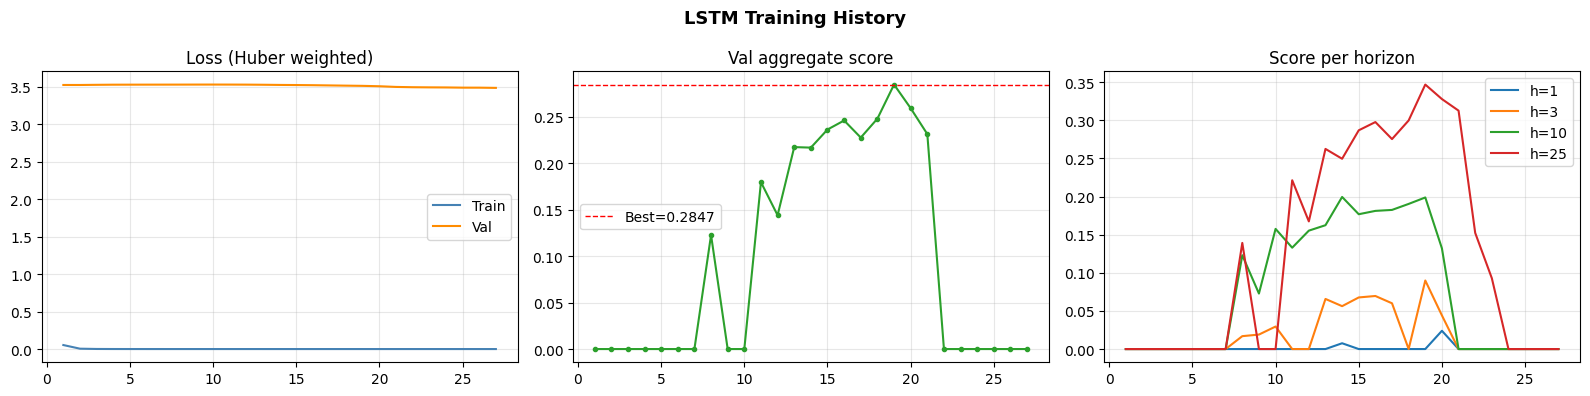

In [17]:
# ============================================================
# TRAINING CURVES
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
eps = list(range(1, len(tr_losses)+1))

axes[0].plot(eps, tr_losses, label='Train', color='steelblue', lw=1.5)
axes[0].plot(eps, va_losses, label='Val',   color='darkorange', lw=1.5)
axes[0].set_title('Loss (Huber weighted)'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(eps, va_scores, color='#2ca02c', marker='o', ms=3, lw=1.5)
axes[1].axhline(best_score, color='red', ls='--', lw=1, label=f'Best={best_score:.4f}')
axes[1].set_title('Val aggregate score'); axes[1].legend(); axes[1].grid(alpha=0.3)

colors_h = {1:'#1f77b4', 3:'#ff7f0e', 10:'#2ca02c', 25:'#d62728'}
for h in HORIZONS:
    axes[2].plot(eps, per_h_hist[h], label=f'h={h}', color=colors_h[h], lw=1.5)
axes[2].set_title('Score per horizon'); axes[2].legend(); axes[2].grid(alpha=0.3)

plt.suptitle('LSTM Training History', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'lstm_curves.png', dpi=100, bbox_inches='tight')
plt.show()

In [18]:
# ============================================================
# CALIBRATION
# ============================================================
ckpt = torch.load(best_path, map_location=DEVICE)
model.load_state_dict(ckpt['model_state'])
model.eval()
print(f'Loaded best model (epoch={ckpt["epoch"]}, score={ckpt["val_score"]:.5f})')

_, _, _, best_vp, best_vt, best_vw = run_epoch(model, val_loader, is_train=False)

# Denormalize tr\u01b0\u1edbc calibration
best_vp_orig = np.column_stack([
    best_vp[:,H2I[h]] * H_TARGET_STD[h] + H_TARGET_MEAN[h] for h in HORIZONS
])
best_vt_orig = np.column_stack([
    best_vt[:,H2I[h]] * H_TARGET_STD[h] + H_TARGET_MEAN[h] for h in HORIZONS
])

calib_params = {}
print(f'\n{"h":>4} | {"a":>8} | {"b":>10} | {"Raw":>8} | {"Calib":>8} | delta')
print('-'*55)
for h in HORIZONS:
    idx  = H2I[h]
    yt = best_vt_orig[:,idx]; yp = best_vp_orig[:,idx]; ww = best_vw[:,idx]
    raw  = weighted_rmse_score(yt, yp, ww)
    a, b = weighted_linear_calibration(yt, yp, ww)
    cal  = weighted_rmse_score(yt, a*yp+b, ww)
    calib_params[h] = (a, b)
    print(f'{h:>4} | {a:>8.4f} | {b:>10.6f} | {raw:>8.5f} | {cal:>8.5f} | {cal-raw:+.5f}')

Loaded best model (epoch=19, score=0.28473)

   h |        a |          b |      Raw |    Calib | delta
-------------------------------------------------------
   1 |   0.4491 |   0.000002 |  0.00000 |  0.05158 | +0.05158
   3 |   0.6084 |   0.000011 |  0.08988 |  0.11806 | +0.02817
  10 |   0.8311 |  -0.000021 |  0.19876 |  0.20299 | +0.00422
  25 |   1.0735 |  -0.000434 |  0.34681 |  0.35251 | +0.00571


In [19]:
# ============================================================
# INFERENCE TEST SET (OOM-SAFE: GROUP BY GROUP)
# ============================================================
print('Inference on test set (group-by-group, OOM-safe)...')
model.eval()

# Pre-index train history
train_hist_idx = {}
for (c, sc, scat), grp in train.groupby(BASE_COLS, sort=False):
    train_hist_idx[(c,sc,scat)] = (
        grp.sort_values(TIME_COL)[SEQ_FEAT_COLS].values.astype(np.float32)
    )

submission_rows = []
total_g = test.groupby(BASE_COLS).ngroups

with torch.no_grad():
    for gi, ((c,sc,scat), tg) in enumerate(test.groupby(BASE_COLS, sort=False)):
        if (gi+1) % 3000 == 0:
            print(f'  {gi+1:,}/{total_g:,}...')
            gc.collect()

        key      = (c, sc, scat)
        hist     = train_hist_idx.get(key, np.zeros((0, N_SEQ_FEATS), np.float32))
        tg       = tg.sort_values(TIME_COL)
        te_feats = tg[SEQ_FEAT_COLS].values.astype(np.float32)
        cat_arr  = tg[CAT_ENC_COLS].values[0].astype(np.int64)
        ids_col  = tg[ID_COL].values
        hor_col  = tg['horizon'].values
        T        = len(tg)

        # Build sequences
        seqs_local = []
        for t in range(T):
            ctx = np.vstack([hist, te_feats[:t]]) if t > 0 else hist
            if len(ctx) >= SEQ_LEN:
                seq = ctx[-SEQ_LEN:]
            else:
                pad = np.zeros((SEQ_LEN-len(ctx), N_SEQ_FEATS), np.float32)
                seq = np.vstack([pad, ctx]) if len(ctx) > 0 else pad
            seqs_local.append(seq)

        seq_t = torch.from_numpy(np.stack(seqs_local)).to(DEVICE)
        cat_t = torch.from_numpy(cat_arr).unsqueeze(0).expand(T,-1).to(DEVICE)

        if USE_AMP:
            with autocast():
                preds_norm = model(seq_t, cat_t).cpu().float().numpy()
        else:
            preds_norm = model(seq_t, cat_t).cpu().numpy()

        del seq_t, cat_t, seqs_local

        for t in range(T):
            h     = int(hor_col[t])
            idx   = H2I[h]
            # Denormalize
            p_orig = preds_norm[t, idx] * H_TARGET_STD[h] + H_TARGET_MEAN[h]
            # Calibrate
            a, b   = calib_params.get(h, (1.0, 0.0))
            submission_rows.append({'id': ids_col[t], 'prediction': a*p_orig+b})

submission = pd.DataFrame(submission_rows)
del train_hist_idx, submission_rows; gc.collect()

assert submission['prediction'].isna().sum() == 0
assert submission['id'].duplicated().sum() == 0
submission.to_csv(OUTPUT_DIR/'submission_lstm.csv', index=False)

print(f'\n\u2705 submission_lstm.csv saved  ({len(submission):,} rows)')
print(f'  mean={submission["prediction"].mean():.4f}  '
      f'std={submission["prediction"].std():.4f}  '
      f'min={submission["prediction"].min():.3f}  '
      f'max={submission["prediction"].max():.3f}')
display(submission.head(5))

Inference on test set (group-by-group, OOM-safe)...

✅ submission_lstm.csv saved  (1,447,107 rows)
  mean=-0.0486  std=0.1715  min=-1.089  max=0.225


,id,prediction
0,10BAVIDU__07YQ9WA4__DPPUO5X2__3__4175,0.001182
1,10BAVIDU__07YQ9WA4__DPPUO5X2__10__4175,-0.074750
2,10BAVIDU__07YQ9WA4__DPPUO5X2__1__4175,-0.017859
3,10BAVIDU__07YQ9WA4__DPPUO5X2__25__4175,-0.924316
4,10BAVIDU__07YQ9WA4__DPPUO5X2__3__4176,-0.081198


  LSTM  Aggregate (val): 0.29095
  LGBM  Aggregate (val): 0.84850
  Gap                  : +0.55755

       h |     LSTM |     LGBM | Diff
------------------------------------------
       1 |  0.05158 |  0.06000 | +0.00842
       3 |  0.11806 |  0.67300 | +0.55494
      10 |  0.20299 |  0.86200 | +0.65901
      25 |  0.35251 |  0.92200 | +0.56949


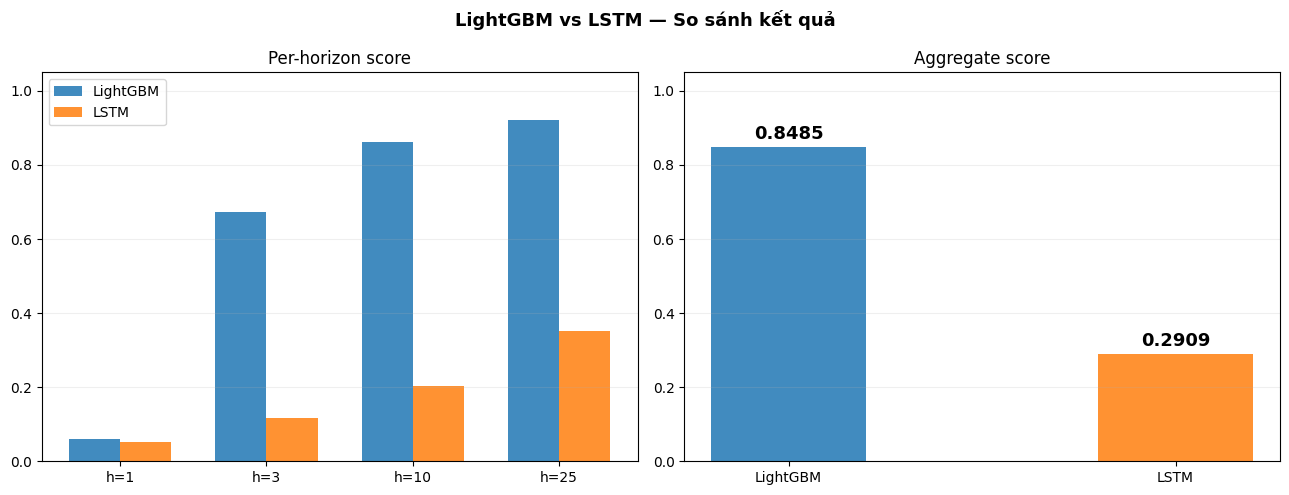

,Model,Aggregate Score,h=1,h=3,h=10,h=25,Features,Loss,Scaling
0,LightGBM (5-seed),0.848497,0.06000,0.67300,0.86200,0.92200,199 engineered,Weighted RMSE,None (tree)
1,LSTM (ep=19),0.290950,0.05158,0.11806,0.20299,0.35251,30x91 seq + calib,Weighted Huber,RobustScaler + target norm


In [20]:
# ============================================================
# K\u1ebeT QU\u1ea2 & SO S\u00c1NH LIGHTGBM
# ============================================================
LGBM = {'agg': 0.848497, 1: 0.060, 3: 0.673, 10: 0.862, 25: 0.922}

# Calibrated aggregate score
calib_all = np.column_stack([
    calib_params[h][0]*best_vp_orig[:,H2I[h]] + calib_params[h][1]
    for h in HORIZONS
])
lstm_agg = weighted_rmse_score(best_vt_orig.ravel(), calib_all.ravel(), best_vw.ravel())
lstm_h   = {
    h: weighted_rmse_score(
        best_vt_orig[:,H2I[h]], calib_all[:,H2I[h]], best_vw[:,H2I[h]]
    )
    for h in HORIZONS
}

print('='*62)
print(f'  LSTM  Aggregate (val): {lstm_agg:.5f}')
print(f'  LGBM  Aggregate (val): {LGBM["agg"]:.5f}')
print(f'  Gap                  : {LGBM["agg"]-lstm_agg:+.5f}')
print()
print(f'  {"h":>6} | {"LSTM":>8} | {"LGBM":>8} | Diff')
print('-'*42)
for h in HORIZONS:
    print(f'  {h:>6} | {lstm_h[h]:>8.5f} | {LGBM[h]:>8.5f} | {LGBM[h]-lstm_h[h]:+.5f}')
print('='*62)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x = np.arange(4); w2 = 0.35
axes[0].bar(x-w2/2, [LGBM[h] for h in HORIZONS],  w2, label='LightGBM', color='#1f77b4', alpha=0.85)
axes[0].bar(x+w2/2, [lstm_h[h] for h in HORIZONS], w2, label='LSTM',     color='#ff7f0e', alpha=0.85)
axes[0].set_xticks(x); axes[0].set_xticklabels([f'h={h}' for h in HORIZONS])
axes[0].set_ylim(0, 1.05); axes[0].legend(); axes[0].set_title('Per-horizon score')
axes[0].grid(alpha=0.2, axis='y')

bars = axes[1].bar(['LightGBM','LSTM'], [LGBM['agg'], lstm_agg],
                   color=['#1f77b4','#ff7f0e'], width=0.4, alpha=0.85)
for bar, sc in zip(bars, [LGBM['agg'], lstm_agg]):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                 f'{sc:.4f}', ha='center', va='bottom', fontsize=13, fontweight='bold')
axes[1].set_ylim(0, 1.05); axes[1].set_title('Aggregate score')
axes[1].grid(alpha=0.2, axis='y')

plt.suptitle('LightGBM vs LSTM \u2014 So s\u00e1nh k\u1ebft qu\u1ea3', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'model_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

# Summary table
summary = pd.DataFrame({
    'Model'          : ['LightGBM (5-seed)', f'LSTM (ep={ckpt["epoch"]})'],
    'Aggregate Score': [LGBM['agg'], round(lstm_agg, 5)],
    **{f'h={h}': [LGBM[h], round(lstm_h[h], 5)] for h in HORIZONS},
    'Features'       : ['199 engineered', f'{SEQ_LEN}x{N_SEQ_FEATS} seq + calib'],
    'Loss'           : ['Weighted RMSE', 'Weighted Huber'],
    'Scaling'        : ['None (tree)', 'RobustScaler + target norm'],
})
display(summary)